In [ ]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from boxbox.loading import load_json

In [ ]:
from boxbox.loading import load_json

race_data = load_json(
    "../data/british_gp/session_laptimes.json"
)

type(race_data)



In [ ]:
import pandas as pd

df = pd.DataFrame(race_data)


In [59]:
import importlib
import boxbox.cleaning
import boxbox.analysis

importlib.reload(boxbox.cleaning)
importlib.reload(boxbox.analysis)

<module 'boxbox.analysis' from 'c:\\Users\\enric\\Desktop\\Box_Box\\boxbox\\analysis.py'>

In [ ]:
from boxbox.cleaning import prepare_lap_data
from boxbox.cleaning import remove_pit_laps
from boxbox.cleaning import remove_neutralised_laps
from boxbox.cleaning import add_fuel_correction
from boxbox.cleaning import add_pace_loss

laps = prepare_lap_data(df)
laps = remove_pit_laps(laps)
laps = remove_neutralised_laps(laps)
laps = add_fuel_correction(laps)
laps = add_pace_loss(laps)


In [60]:
from boxbox.analysis import degradation_regression
from boxbox.analysis import compare_driver_compounds

In [ ]:
laps["status"] = pd.to_numeric(
    laps["status"],
    errors="coerce"
)


Tyre Age vs Pace Loss - Charles Leclerc

In [50]:
# Analysis dataset
degradation_data = laps[
    laps["life"] > 1
].copy()

# Select Leclerc from the filtered dataset
lec = degradation_data[
    degradation_data["drv"] == "LEC"
]

# Separate compounds
medium = lec[
    lec["compound"] == "MEDIUM"
]

hard = lec[
    lec["compound"] == "HARD"
]

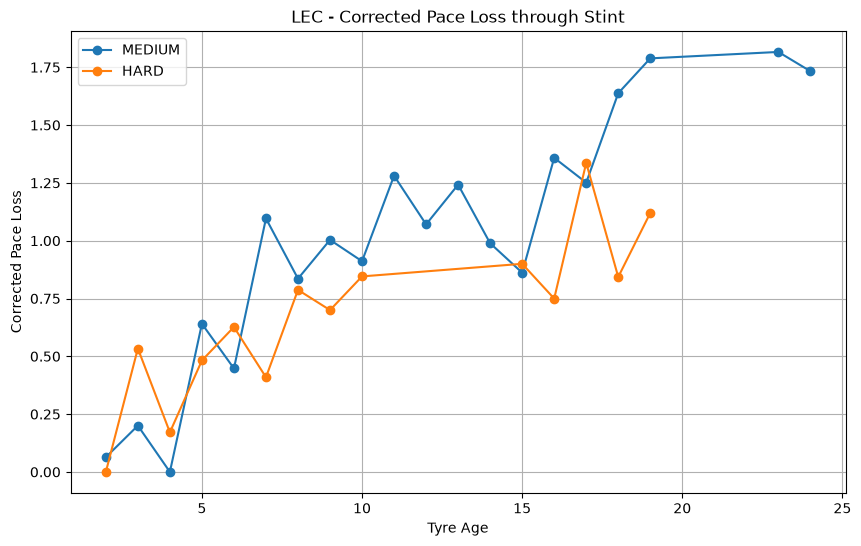

In [61]:
plt.figure(figsize=(10,6))

for compound in lec["compound"].unique():

    subset = lec[
        lec["compound"] == compound
    ].sort_values("life")

    plt.plot(
        subset["life"],
        subset["corrected_pace_loss"],
        marker="o",
        label=compound
    )

plt.xlabel("Tyre Age")
plt.ylabel("Corrected Pace Loss")
plt.title("LEC - Corrected Pace Loss through Stint")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from scipy.stats import linregress

In [62]:
medium_fit = linregress(
    medium["life"],
    medium["corrected_pace_loss"]
)

hard_fit = linregress(
    hard["life"],
    hard["corrected_pace_loss"]
)

print("Medium slope:", medium_fit.slope)
print("Medium R²:", medium_fit.rvalue**2)

print("Hard slope:", hard_fit.slope)
print("Hard R²:", hard_fit.rvalue**2)

Medium slope: 0.07616595188896243
Medium R²: 0.8209488727879783
Hard slope: 0.04939798862615962
Hard R²: 0.699455541189876


In [ ]:
from scipy.stats import linregress
import numpy as np
import matplotlib.pyplot as plt

medium = lec[
    lec["compound"] == "MEDIUM"
]

fit = linregress(
    medium["life"],
    medium["corrected_pace_loss"]
)

x = np.array(medium["life"])
y = fit.intercept + fit.slope * x

plt.figure(figsize=(8, 5))

plt.scatter(
    medium["life"],
    medium["corrected_pace_loss"],
    label="Medium Laps"
)

plt.plot(
    x,
    y,
    color="red",
    label="Regression Line"
)

plt.xlabel("Tyre Age")
plt.ylabel("Pace Loss")
plt.title("LEC Medium Tyre Degradation")

plt.legend()

plt.show()

print(
    f"Slope: {fit.slope:.4f}"
)

print(
    f"R²: {fit.rvalue**2:.3f}"
)

In [53]:
nor = degradation_data[
    degradation_data["drv"] == "NOR"
]
print(
    degradation_regression(
        nor,
        "MEDIUM"
    )
)

print(
    degradation_regression(
        nor,
        "HARD"
    )
)

{'compound': 'MEDIUM', 'slope': np.float64(0.04035967939441195), 'r_squared': np.float64(0.45925810360973823), 'intercept': np.float64(0.2741977942462748)}
{'compound': 'HARD', 'slope': np.float64(0.15286373626373972), 'r_squared': np.float64(0.7774186501650807), 'intercept': np.float64(-0.13115604395605374)}


In [63]:
lec_results = compare_driver_compounds(
    "LEC",
    lec
)

nor_results = compare_driver_compounds(
    "NOR",
    nor
)

pd.concat(
    [lec_results, nor_results]
)

,driver,compound,slope,r_squared,intercept
0,LEC,MEDIUM,0.076166,0.820949,0.112592
1,LEC,HARD,0.049398,0.699456,0.188466
0,NOR,MEDIUM,0.040360,0.459258,0.274198
1,NOR,HARD,0.152864,0.777419,-0.131156
